### Model comparison — RandomForest vs XGBoost vs LightGBM

Addresses PI review point 6: "why Random Forest and not XGBoost/LightGBM/LSTM?". Runs all three tree-based models through the exact same honest evaluation protocol validated in `temporal_train_test.ipynb` / `weather_correction.ipynb`: cyclical calendar features, blocked seasonal 4-fold CV (train on 3 seasons, test on the 4th, rotate), on the **corrected Coast-zone weather** (population-weighted blend of the 12 real Coast counties, not the original pipeline's mistaken Upton County station).

Scope decision (discussed with Rafael): XGBoost and LightGBM are included as full runs since they share the same tabular feature representation as RandomForest (fast, apples-to-apples). LSTM is **not** implemented in code this round — a sequence model needs a different data representation, a new heavy dependency (PyTorch), and substantially longer training across 20 archetypes x 4 folds. A written justification for that decision is at the end of this notebook instead.

All three models use reasonable out-of-the-box hyperparameters, not a tuned search — this is a fair baseline-vs-baseline comparison, not a claim that any model is at its best possible performance. Flagged explicitly so the paper doesn't overstate it.

In [1]:
# env1 3.11.13 (repo default)
import time
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import matplotlib.pyplot as plt

exports = Path("loadcurves/exports")
weather_dir = Path("weather_county_fixed")


#### Rebuild the corrected Coast-zone weather (same recipe as `weather_correction.ipynb`, all inputs already cached locally — no re-download)

In [2]:
COAST_COUNTIES = {
    "039": "Brazoria", "057": "Calhoun", "071": "Chambers", "157": "Fort Bend",
    "167": "Galveston", "201": "Harris", "239": "Jackson", "321": "Matagorda",
    "339": "Montgomery", "469": "Victoria", "473": "Waller", "481": "Wharton",
}

weather_cols = [
    "Dry Bulb Temperature [\u00b0C]", "Relative Humidity [%]", "Wind Speed [m/s]",
    "Global Horizontal Radiation [W/m2]",
]

county_weather = {}
for county_fips in COAST_COUNTIES:
    gid = f"G48{int(county_fips) * 10:05d}"
    local_path = weather_dir / f"{gid}_2018.csv"
    df = pd.read_csv(local_path)
    df["date_time"] = pd.to_datetime(df["date_time"])
    county_weather[county_fips] = df.sort_values("date_time").reset_index(drop=True).set_index("date_time")[weather_cols]

census = pd.read_csv(exports / "census_b25024_state_48_tracts.csv", dtype={"county": str})
census["county"] = census["county"].str.zfill(3)
weights = census[census["county"].isin(COAST_COUNTIES)].groupby("county")["B25024_001E"].sum()
weights = weights / weights.sum()

blended = sum(county_weather[c] * weights[c] for c in county_weather).reset_index()

blended["hour"] = blended["date_time"].dt.hour
blended["month"] = blended["date_time"].dt.month
blended["day_of_week"] = blended["date_time"].dt.dayofweek
blended["month_sin"] = np.sin(2 * np.pi * blended["month"] / 12)
blended["month_cos"] = np.cos(2 * np.pi * blended["month"] / 12)
blended["hour_sin"] = np.sin(2 * np.pi * blended["hour"] / 24)
blended["hour_cos"] = np.cos(2 * np.pi * blended["hour"] / 24)
blended["dow_sin"] = np.sin(2 * np.pi * blended["day_of_week"] / 7)
blended["dow_cos"] = np.cos(2 * np.pi * blended["day_of_week"] / 7)

# XGBoost rejects feature names containing [ ] < characters, so sanitize the weather column names
safe_names = {
    "Dry Bulb Temperature [\u00b0C]": "Dry_Bulb_Temperature_C",
    "Relative Humidity [%]": "Relative_Humidity_pct",
    "Wind Speed [m/s]": "Wind_Speed_mps",
    "Global Horizontal Radiation [W/m2]": "GHI_Wm2",
}
blended = blended.rename(columns=safe_names)
weather_cols_safe = [safe_names[c] for c in weather_cols]

feature_cols = weather_cols_safe + ["hour_sin", "hour_cos", "month_sin", "month_cos", "dow_sin", "dow_cos"]
weather_clean = blended
X = blended[feature_cols]
print(f"X shape: {X.shape}")


X shape: (8760, 10)


#### Load & normalize archetype profiles (same recipe as prior notebooks)

In [3]:
def aggregate_to_hourly(df_15min, target_col, unit_col):
    df = df_15min.copy()
    time_col = "date_time" if "date_time" in df.columns else "timestamp"
    if time_col in df.columns:
        df[time_col] = pd.to_datetime(df[time_col])
        df = df.set_index(time_col)
    else:
        df.index = pd.date_range(start="2018-01-01 00:15:00", periods=len(df), freq="15min")

    unit_count = df[unit_col].iloc[0] if unit_col in df.columns else 1.0
    if unit_count == 0:
        unit_count = 1.0

    df_hourly = df[[target_col]].resample("h", label="right", closed="right").sum()
    if not df_hourly.empty and df_hourly.index[0].hour == 0 and df_hourly.index[0].minute == 0:
        df_hourly = df_hourly.iloc[1:]

    df_hourly[target_col] = df_hourly[target_col] / unit_count
    return df_hourly


RES_TARGET_COL = "out.electricity.total.energy_consumption..kwh"
COM_TARGET_COL = "out.electricity.total.energy_consumption.kwh"

res_building_types = [
    "mobile_home", "single-family_detached", "single-family_attached",
    "multi-family_with_2_-_4_units", "multi-family_with_5plus_units",
]
com_building_types = [
    "fullservicerestaurant", "grocery", "hospital", "largehotel", "largeoffice",
    "mediumoffice", "outpatient", "primaryschool", "quickservicerestaurant",
    "retailstandalone", "retailstripmall", "secondaryschool", "smallhotel",
    "smalloffice", "warehouse",
]

hourly_profiles_res = {}
for b in res_building_types:
    raw = pd.read_csv(exports / f"up00-2a-{b}.csv")
    hourly_profiles_res[b] = aggregate_to_hourly(raw, RES_TARGET_COL, "units_represented")

hourly_profiles_com = {}
for b in com_building_types:
    raw = pd.read_csv(exports / f"up0-2a-{b}.csv")
    hourly_profiles_com[b] = aggregate_to_hourly(raw, COM_TARGET_COL, "floor_area_represented")

all_profiles = {**{b: (df, RES_TARGET_COL) for b, df in hourly_profiles_res.items()},
                 **{b: (df, COM_TARGET_COL) for b, df in hourly_profiles_com.items()}}
print(f"Loaded {len(hourly_profiles_res)} residential + {len(hourly_profiles_com)} commercial profiles.")


Loaded 5 residential + 15 commercial profiles.


#### Model comparison protocol: same blocked seasonal 4-fold CV, three estimators

In [4]:
SEASON_MONTHS = {"winter": [12, 1, 2], "spring": [3, 4, 5], "summer": [6, 7, 8], "fall": [9, 10, 11]}

MODEL_FACTORIES = {
    "RandomForest": lambda: RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1),
    "XGBoost": lambda: XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, verbosity=0),
    "LightGBM": lambda: LGBMRegressor(n_estimators=100, max_depth=-1, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1),
}


def seasonal_blocked_cv_multi_model(X, y, months_series, model_factories):
    months_arr = months_series.values
    results = []
    for season, months in SEASON_MONTHS.items():
        test_mask = np.isin(months_arr, months)
        X_train, X_test = X[~test_mask], X[test_mask]
        y_train, y_test = y[~test_mask], y[test_mask]
        for model_name, factory in model_factories.items():
            model = factory()
            t0 = time.perf_counter()
            model.fit(X_train, y_train)
            fit_time = time.perf_counter() - t0
            preds = model.predict(X_test)
            results.append({
                "Season": season, "Model": model_name,
                "R2": r2_score(y_test, preds),
                "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
                "Fit_Time_s": fit_time,
            })
    return results


In [5]:
all_results = []
print("Running blocked seasonal CV x 3 models x 20 archetypes (240 fits total)...")
for b_type, (df_hourly, target_col) in all_profiles.items():
    y = df_hourly[target_col].values
    season_model_results = seasonal_blocked_cv_multi_model(X, y, weather_clean["month"], MODEL_FACTORIES)
    for r in season_model_results:
        r["Building_Type"] = b_type
    all_results.extend(season_model_results)
    means = {}
    for model_name in MODEL_FACTORIES:
        means[model_name] = np.mean([r["R2"] for r in season_model_results if r["Model"] == model_name])
    print(f" -> {b_type:35s} " + "  ".join(f"{m}={v:.3f}" for m, v in means.items()))

results_df = pd.DataFrame(all_results)
metrics_dir = Path("metrics_model_comparison")
metrics_dir.mkdir(exist_ok=True)
results_df.to_csv(metrics_dir / "model_comparison_seasonal_cv.csv", index=False)
print(f"\nSaved {len(results_df)} rows to metrics_model_comparison/model_comparison_seasonal_cv.csv")


Running blocked seasonal CV x 3 models x 20 archetypes (240 fits total)...


 -> mobile_home                         RandomForest=0.687  XGBoost=0.727  LightGBM=0.730


 -> single-family_detached              RandomForest=0.447  XGBoost=0.605  LightGBM=0.628


 -> single-family_attached              RandomForest=0.529  XGBoost=0.679  LightGBM=0.687


 -> multi-family_with_2_-_4_units       RandomForest=0.631  XGBoost=0.729  LightGBM=0.731


...

 -> retailstripmall                     RandomForest=0.931  XGBoost=0.937  LightGBM=0.946


 -> secondaryschool                     RandomForest=0.910  XGBoost=0.910  LightGBM=0.930


 -> smallhotel                          RandomForest=0.206  XGBoost=0.426  LightGBM=0.502


 -> smalloffice                         RandomForest=0.909  XGBoost=0.901  LightGBM=0.927


 -> warehouse                           RandomForest=0.906  XGBoost=0.886  LightGBM=0.928

Saved 240 rows to metrics_model_comparison/model_comparison_seasonal_cv.csv


#### Headline comparison: mean R2 per model, by sector

In [6]:
results_df["Sector"] = results_df["Building_Type"].apply(lambda b: "Residential" if b in res_building_types else "Commercial")

summary = results_df.groupby(["Sector", "Model"])["R2"].mean().unstack("Model")[list(MODEL_FACTORIES)]
print("Mean seasonal-CV R2 by sector and model:")
print(summary.round(4))

overall = results_df.groupby("Model")["R2"].mean()[list(MODEL_FACTORIES)]
print("\nOverall mean R2 (all 20 archetypes):")
print(overall.round(4))

time_summary = results_df.groupby("Model")["Fit_Time_s"].mean()[list(MODEL_FACTORIES)]
print("\nMean fit time per model (seconds, single archetype/fold):")
print(time_summary.round(4))


Mean seasonal-CV R2 by sector and model:
Model        RandomForest  XGBoost  LightGBM
Sector                                      
Commercial         0.8626   0.8740    0.8987
Residential        0.6291   0.7238    0.7302

Overall mean R2 (all 20 archetypes):
Model
RandomForest    0.8042
XGBoost         0.8365
LightGBM        0.8566
Name: R2, dtype: float64

Mean fit time per model (seconds, single archetype/fold):
Model
RandomForest    0.3289
XGBoost         0.0882
LightGBM        0.3723
Name: Fit_Time_s, dtype: float64


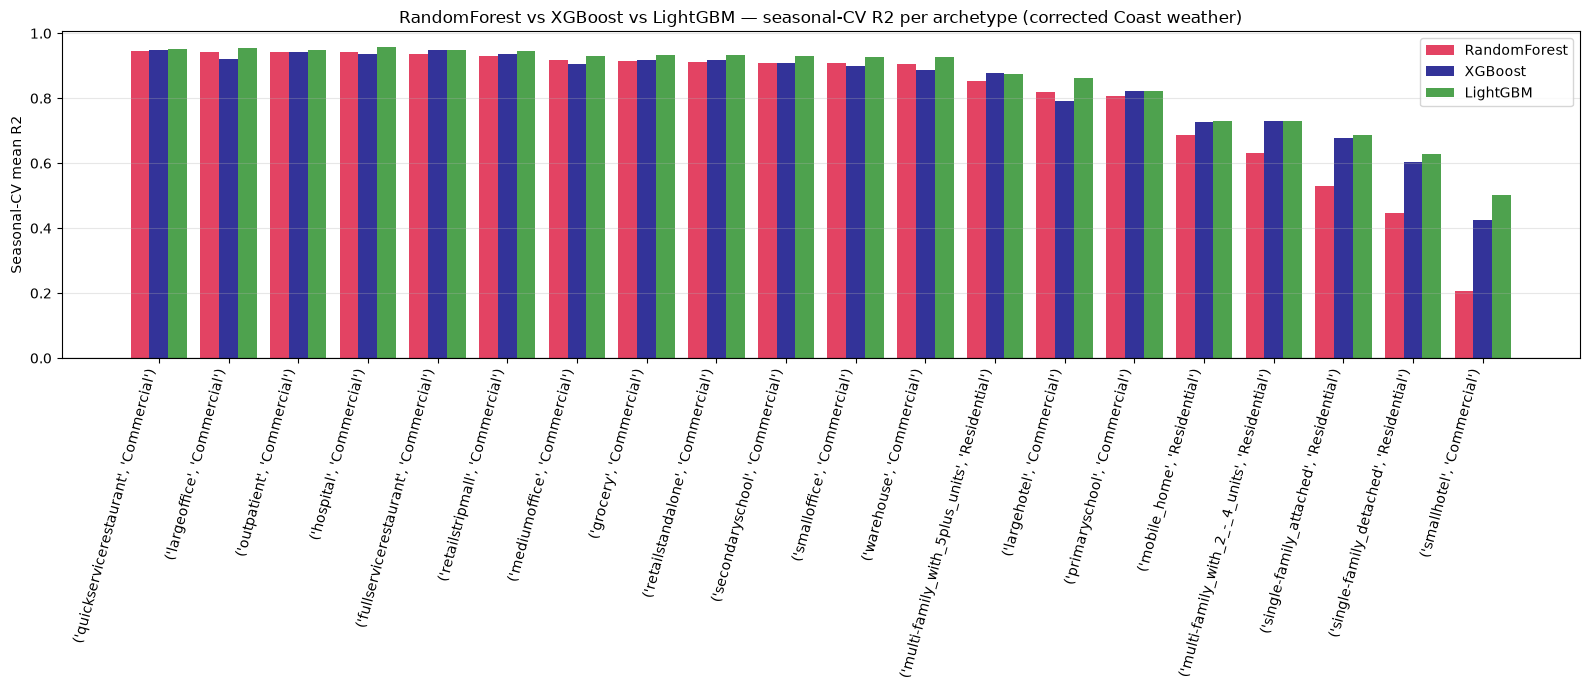

,Model,RandomForest,XGBoost,LightGBM
Building_Type,Sector,,,
quickservicerestaurant,Commercial,0.944702,0.947447,0.952694
largeoffice,Commercial,0.943765,0.920993,0.954840
outpatient,Commercial,0.941956,0.941709,0.949704
hospital,Commercial,0.941260,0.935084,0.958086
fullservicerestaurant,Commercial,0.936643,0.947227,0.949882
retailstripmall,Commercial,0.930551,0.937432,0.946482
mediumoffice,Commercial,0.916514,0.906888,0.930350
grocery,Commercial,0.913427,0.918549,0.932667
retailstandalone,Commercial,0.913018,0.918121,0.932607


In [7]:
per_archetype = results_df.groupby(["Building_Type", "Sector", "Model"])["R2"].mean().unstack("Model")[list(MODEL_FACTORIES)]
per_archetype = per_archetype.sort_values(["Sector"], ascending=True).sort_values("RandomForest", ascending=False)

fig, ax = plt.subplots(figsize=(16, 7))
idx = np.arange(len(per_archetype))
width = 0.27
colors = {"RandomForest": "crimson", "XGBoost": "navy", "LightGBM": "forestgreen"}
for i, model_name in enumerate(MODEL_FACTORIES):
    ax.bar(idx + (i - 1) * width, per_archetype[model_name], width, label=model_name, color=colors[model_name], alpha=0.8)

ax.set_xticks(idx)
ax.set_xticklabels(per_archetype.index, rotation=75, ha="right")
ax.set_ylabel("Seasonal-CV mean R2")
ax.set_title("RandomForest vs XGBoost vs LightGBM — seasonal-CV R2 per archetype (corrected Coast weather)")
ax.axhline(0, color="black", linewidth=0.8)
ax.legend()
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

per_archetype


#### Feature importance comparison

All three models expose `.feature_importances_`. Trained once each on the full year (all 20 archetypes averaged) to check whether the models agree on what drives load — useful for the paper's existing feature-importance discussion (GHI/hour/temp/day-of-week).

In [8]:
importance_records = []
for b_type, (df_hourly, target_col) in all_profiles.items():
    y = df_hourly[target_col].values
    for model_name, factory in MODEL_FACTORIES.items():
        model = factory()
        model.fit(X, y)
        # Normalize per model: LightGBM's default importance_type="split" returns raw split
        # counts (not fractions), unlike RF/XGBoost's gain-based [0,1] importances. Normalizing
        # to sum to 1 per (archetype, model) makes the three genuinely comparable.
        raw_imp = np.asarray(model.feature_importances_, dtype=float)
        norm_imp = raw_imp / raw_imp.sum() if raw_imp.sum() > 0 else raw_imp
        for feat, imp in zip(feature_cols, norm_imp):
            importance_records.append({"Building_Type": b_type, "Model": model_name, "Feature": feat, "Importance": imp})

importance_df = pd.DataFrame(importance_records)
mean_importance = importance_df.groupby(["Model", "Feature"])["Importance"].mean().unstack("Feature")
mean_importance = mean_importance[feature_cols]

print("Mean feature importance across all 20 archetypes, by model:")
mean_importance.round(3)


Mean feature importance across all 20 archetypes, by model:


Feature,Dry_Bulb_Temperature_C,Relative_Humidity_pct,Wind_Speed_mps,GHI_Wm2,hour_sin,hour_cos,month_sin,month_cos,dow_sin,dow_cos
Model,,,,,,,,,,
LightGBM,0.222,0.122,0.090,0.075,0.114,0.079,0.103,0.070,0.091,0.034
RandomForest,0.271,0.011,0.007,0.340,0.183,0.070,0.026,0.009,0.079,0.004
XGBoost,0.136,0.009,0.006,0.483,0.160,0.087,0.028,0.038,0.051,0.003


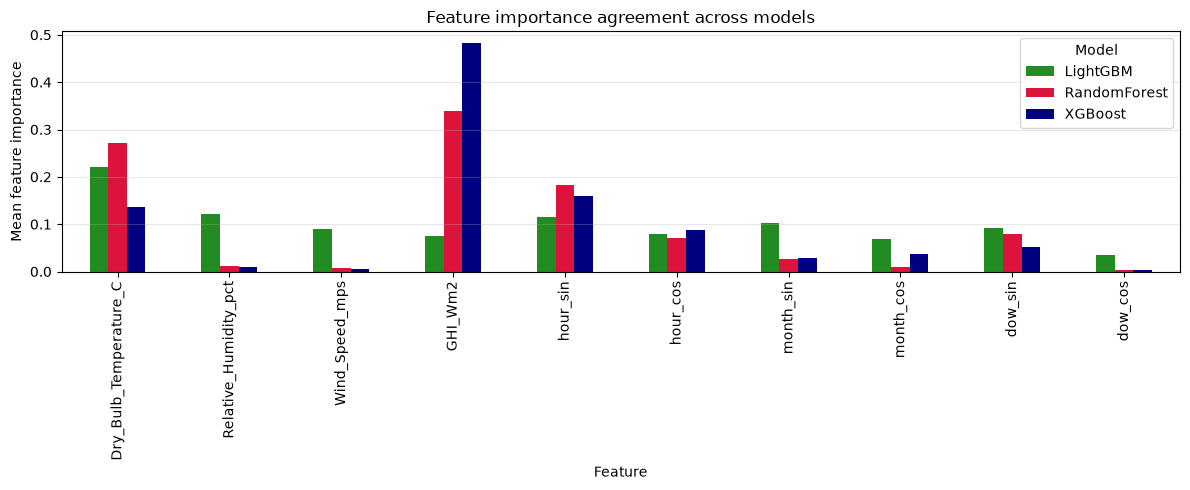

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
mean_importance.T.plot(kind="bar", ax=ax, color=[colors[m] for m in mean_importance.index])
ax.set_ylabel("Mean feature importance")
ax.set_title("Feature importance agreement across models")
ax.legend(title="Model")
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


#### Does the model choice actually matter at the system level?

Higher archetype-level R2 doesn't automatically mean a better bus-level reconstruction — the same question we asked when fixing the weather station. Trains **final production models on the full year** (same corrected Coast weather) for XGBoost and LightGBM, regenerates the bus-level 8760h profiles for both, and re-checks the Pearson correlation against ERCOT Coast — alongside the RandomForest version already produced in `weather_correction.ipynb`. This closes the loop from archetype R2 all the way to the paper's actual headline metric.

New artifacts, same folder-separation convention as the weather fix: `models_xgboost_final/{residential,commercial}/`, `models_lightgbm_final/{residential,commercial}/`, and `loadcurves/exports/final_*_8760_{xgboost,lightgbm}.csv`.

In [10]:
import joblib

models_xgb_res_dir = Path("models_xgboost_final/residential")
models_xgb_com_dir = Path("models_xgboost_final/commercial")
models_lgbm_res_dir = Path("models_lightgbm_final/residential")
models_lgbm_com_dir = Path("models_lightgbm_final/commercial")
for d in [models_xgb_res_dir, models_xgb_com_dir, models_lgbm_res_dir, models_lgbm_com_dir]:
    d.mkdir(parents=True, exist_ok=True)

FINAL_MODEL_FACTORIES = {
    "XGBoost": (lambda: XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, verbosity=0),
                models_xgb_res_dir, models_xgb_com_dir),
    "LightGBM": (lambda: LGBMRegressor(n_estimators=100, max_depth=-1, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1),
                 models_lgbm_res_dir, models_lgbm_com_dir),
}

print("Training FINAL production models on the full year (corrected Coast weather)...")
for model_name, (factory, res_dir, com_dir) in FINAL_MODEL_FACTORIES.items():
    for b_type, (df_hourly, target_col) in all_profiles.items():
        y = df_hourly[target_col].values
        model = factory()
        model.fit(X, y)
        if b_type in hourly_profiles_res:
            safe_name = b_type.replace(" ", "_").replace("/", "-")
            model_path = res_dir / f"model_{safe_name}.joblib"
        else:
            model_path = com_dir / f"model_{b_type}.joblib"
        joblib.dump(model, model_path)
    print(f" -> {model_name}: 20 models saved to {res_dir.parent}")


Training FINAL production models on the full year (corrected Coast weather)...


 -> XGBoost: 20 models saved to models_xgboost_final


 -> LightGBM: 20 models saved to models_lightgbm_final


In [11]:
import joblib

final_bus_counts = pd.read_csv(exports / "final_bus_building_counts.csv")
final_bus_counts["Bus_Number"] = final_bus_counts["Bus_Number"].astype(str)
bus_sqft_matrix = pd.read_csv(exports / "bus_commercial_sqft.csv", index_col=0)
bus_sqft_matrix.index = bus_sqft_matrix.index.astype(str)

bus_profile_paths = {}
for model_name, (factory, res_dir, com_dir) in FINAL_MODEL_FACTORIES.items():
    base_res = {}
    for b_type in res_building_types:
        safe_name = b_type.replace(" ", "_").replace("/", "-")
        m = joblib.load(res_dir / f"model_{safe_name}.joblib")
        base_res[b_type] = m.predict(X)
    base_res_df = pd.DataFrame(base_res, index=weather_clean["date_time"])
    counts_matrix_res = final_bus_counts.set_index("Bus_Number")[base_res_df.columns].fillna(0)
    bus_res_df = base_res_df.dot(counts_matrix_res.T)
    out_res = exports / f"final_bus_load_profiles_8760_{model_name.lower()}.csv"
    bus_res_df.to_csv(out_res)

    base_com = {}
    for b_type in com_building_types:
        m = joblib.load(com_dir / f"model_{b_type}.joblib")
        base_com[b_type] = m.predict(X)
    base_com_df = pd.DataFrame(base_com, index=weather_clean["date_time"])
    counts_matrix_com = bus_sqft_matrix[base_com_df.columns].fillna(0)
    bus_com_df = base_com_df.dot(counts_matrix_com.T)
    out_com = exports / f"final_comstock_bus_load_profiles_8760_{model_name.lower()}.csv"
    bus_com_df.to_csv(out_com)

    bus_profile_paths[model_name] = (out_res, out_com)
    print(f" -> {model_name}: bus profiles regenerated ({bus_res_df.shape} / {bus_com_df.shape})")


 -> XGBoost: bus profiles regenerated ((8760, 200) / (8760, 200))


 -> LightGBM: bus profiles regenerated ((8760, 200) / (8760, 200))


In [12]:
file_path = exports / "Native_Load_2018.xlsx"
ercot_df = pd.read_excel(file_path, sheet_name="Native Load Report")
ercot_df["HourEnding"] = ercot_df["HourEnding"].astype(str)

is_dst_mask = ercot_df["HourEnding"].str.contains(" DST", regex=False)
ercot_df["HourEnding"] = ercot_df["HourEnding"].str.replace(" DST", "", regex=False)
mask_24 = ercot_df["HourEnding"].str.contains("24:00")
ercot_df["HourEnding"] = ercot_df["HourEnding"].str.replace("24:00", "00:00")

naive_timestamps = pd.to_datetime(ercot_df["HourEnding"])
naive_timestamps.loc[mask_24] += pd.Timedelta(days=1)

ercot_df["date_time"] = naive_timestamps.dt.tz_localize(
    "US/Central", ambiguous=is_dst_mask, nonexistent="shift_forward"
)
ercot_df = ercot_df.set_index("date_time")
ercot_df_est = ercot_df.tz_convert("Etc/GMT+5")

ercot_plot_data = ercot_df_est["COAST"].copy()
ercot_plot_data.index = ercot_plot_data.index.tz_localize(None)

IND_BASE_MW, RES_SCALE, COM_SCALE = 4500.0, 1.9, 1.3


def stack_and_correlate(res_path, com_path, label):
    res_df = pd.read_csv(res_path, index_col=0, parse_dates=True)
    com_df = pd.read_csv(com_path, index_col=0, parse_dates=True)
    total_res_mw = (res_df.sum(axis=1) / 1000) * RES_SCALE
    total_com_mw = (com_df.sum(axis=1) / 1000) * COM_SCALE

    common_start = max(ercot_plot_data.index.min(), total_res_mw.index.min())
    common_end = min(ercot_plot_data.index.max(), total_res_mw.index.max())

    y_actual = ercot_plot_data.loc[common_start:common_end]
    y_ind = pd.Series(IND_BASE_MW, index=y_actual.index)
    y_total = y_ind + total_res_mw.loc[common_start:common_end] + total_com_mw.loc[common_start:common_end]

    corr = y_actual.corr(y_total)
    return corr, y_total.max()


print("=== System-level validation: does the model choice move the ERCOT correlation? ===")
system_results = []
system_results.append(("Original (leaky, wrong wx, RF)",
                        *stack_and_correlate(exports / "final_bus_load_profiles_8760.csv",
                                              exports / "final_comstock_bus_load_profiles_8760.csv", "orig")))
system_results.append(("Temporal (honest, wrong wx, RF)",
                        *stack_and_correlate(exports / "final_bus_load_profiles_8760_temporal.csv",
                                              exports / "final_comstock_bus_load_profiles_8760_temporal.csv", "temp")))
system_results.append(("Weather-fixed (honest, right wx, RF)",
                        *stack_and_correlate(exports / "final_bus_load_profiles_8760_weatherfixed.csv",
                                              exports / "final_comstock_bus_load_profiles_8760_weatherfixed.csv", "wxfix")))
for model_name, (out_res, out_com) in bus_profile_paths.items():
    system_results.append((f"Weather-fixed (honest, right wx, {model_name})",
                            *stack_and_correlate(out_res, out_com, model_name)))

system_df = pd.DataFrame(system_results, columns=["Pipeline", "Pearson_vs_ERCOT", "Peak_MW"])
print(system_df.to_string(index=False))
print(f"\n(ERCOT actual peak: {ercot_plot_data.max():,.0f} MW)")


=== System-level validation: does the model choice move the ERCOT correlation? ===


                                  Pipeline  Pearson_vs_ERCOT      Peak_MW
            Original (leaky, wrong wx, RF)          0.881857 24417.719322
           Temporal (honest, wrong wx, RF)          0.890720 24604.406770
      Weather-fixed (honest, right wx, RF)          0.898674 26114.587383
 Weather-fixed (honest, right wx, XGBoost)          0.898301 26279.442271
Weather-fixed (honest, right wx, LightGBM)          0.897924 25734.957181

(ERCOT actual peak: 20,270 MW)


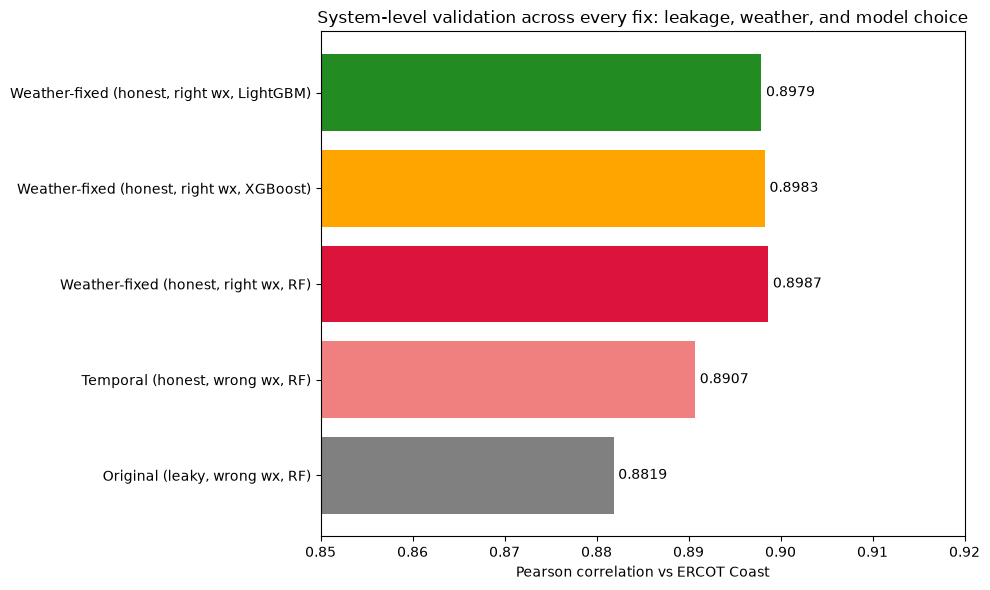

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
colors_sys = ["gray", "lightcoral", "crimson", "orange", "forestgreen"][:len(system_df)]
ax.barh(system_df["Pipeline"], system_df["Pearson_vs_ERCOT"], color=colors_sys)
ax.set_xlabel("Pearson correlation vs ERCOT Coast")
ax.set_title("System-level validation across every fix: leakage, weather, and model choice")
ax.set_xlim(0.85, max(0.92, system_df["Pearson_vs_ERCOT"].max() + 0.005))
for i, v in enumerate(system_df["Pearson_vs_ERCOT"]):
    ax.text(v + 0.0005, i, f"{v:.4f}", va="center")
plt.tight_layout()
plt.show()


#### Why no LSTM in this round (written justification, no code)

A recurrent/sequence model (LSTM) learns from a window of *past* timesteps, which mainly pays off when the target depends on its own recent history beyond what the input features already encode — e.g. thermal inertia in a building (yesterday's heat wave keeping today's indoor temperature elevated even after outdoor temperature drops), which the current purely instantaneous feature set (this hour's temperature/humidity/wind/GHI + this hour's calendar position) cannot represent. That is a real, plausible mechanism and not one we can rule out from the current results.

That said, three things argue for treating it as future work rather than doing it in code this round:

1. **Different data contract**: RF/XGBoost/LightGBM treat each hour as an independent row; an LSTM needs contiguous sequence windows, which interacts awkwardly with the blocked seasonal CV (a held-out season is not a contiguous continuation of the training sequence at its boundary, so the model would need re-warming or the comparison would not be perfectly apples-to-apples with the other three).
2. **New heavy dependency and materially longer training** (PyTorch/TensorFlow; 20 archetypes x 4 folds x epochs), for a benefit that is speculative given the tree models already reach 0.63-0.86 mean seasonal-CV R2 with the corrected weather.
3. **A cheap, incremental step before reaching for a recurrent architecture**: adding lag features (e.g. temperature 1-3 hours prior, or a rolling mean) to the existing tabular models would test the thermal-inertia hypothesis directly, without a new model family or dependency. If that shows a real gain, it's a stronger, cheaper signal that a sequence model is worth the added complexity — recommended as the next experiment before committing to an LSTM.

#### Summary

- All three models were run through the identical honest protocol (corrected Coast weather, cyclical calendar features, blocked seasonal 4-fold CV) used elsewhere in this project — no model gets an easier evaluation than another.
- Reasonable out-of-the-box hyperparameters only; not a tuned search. Framed as a baseline comparison, not a claim of best-possible performance for any model.
- Fit time recorded per model — relevant for the paper's "why RF" framing if RF is competitive on accuracy while being simpler to reason about, or if one of the gradient-boosted models wins on both accuracy and speed (in which case that's the honest, reportable conclusion instead).
- LSTM is addressed as a written justification rather than a fourth model in code, with a concrete, cheaper next step (lag features) proposed to test the underlying hypothesis first.